# LASSI - Power Efficiency

***OLLAMA API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

## Setup

In [8]:
import os

# Import LASSI modules
import lassi.llm_config
import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline
%aimport lassi.get_power

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [9]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.

    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- DNU -- mallocFree ["10000"]
    -- layout ["1"]
    -- atomicCost ["1"]
    -- dense-embedding ["10000", "8", "1"]
    -- pathfinder ["10000", "1000", "1000"]
    -- bsearch ["10000", "1"]
    -- entropy ["10000", "1024", "1"]
    -- colorwheel ["10000", "8", "1"]
    -- randomAccess ["1"]
    -- lid-driven-cavity [""]
    """
    
    app_folder_name = "lid-driven-cavity"

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    if source_lang == "CUDA":
        code_compiler = "nvcc"
        code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_60 -O3"
        # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
        # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    model = "gpt4o"  # (max token = 128000)
    model_coder = "gpt4o"  # (max token = 128000)
    # model = "gpto1preview"  # (max token = 128000)

    # -- FROM OLLAMA
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000
    num_ctx_coder = 128000

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "02test_betterpower_withcontext"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder, llm_source, use_context,
            context_knowledge_selection, code_compiler, code_compiler_kwds, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Application: lid-driven-cavity

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpt4o
Model coder: gpt4o
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpt4o/promptset_CUDA/lid-driven-cavity-cuda_main_ee_refactorcode_CUDA_exp02test_betterpower_withcontext

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

LLM Prompt for Code Generation: 

Carefully follow all these instructions step-by-step: 
STEP 1. Read the background knowledge and your background knowledge summaries about programming and energy-efficiency strategies. 
STEP 2. Read your description and analysis of the sour

Waiting for the system to settle down...: 100%|████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Execute command: ['./lid-driven-cavity-cuda_main', '']

Problem size: 512 x 512 
Time = 0.000477, delt = 4.768372e-04, iter = 1, res = 0.000000e+00
Time = 0.000954, delt = 4.768372e-04, iter = 1, res = 0.000000e+00
Time = 0.001000, delt = 4.632568e-05, iter = 1, res = 0.000000e+00

Total execution time of the iteration loop: 0.002207 (s)
GPU power data has been written to source_CUDA_gpu_power_results.csv


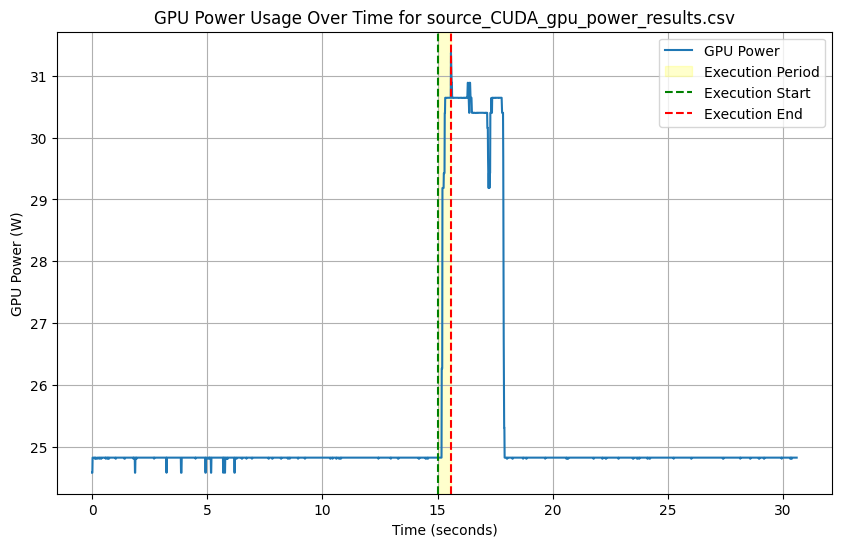

Start time: 15.0 -- End time: 15.595

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 0.59 seconds
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000005 kWh
  0.0048 Wh
  17.12 J
Average GPU power: 29.29 W
Total Energy During Exe Runtime:   17.12 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 0.59
GPU power data has been written to idle__gpu_power_results.csv


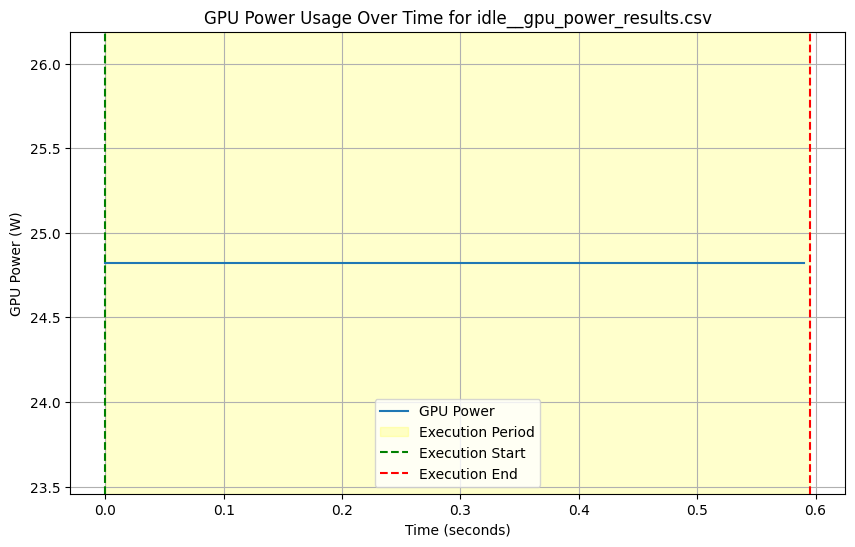

Start time: 0 -- End time: 0.595

Capturing idle energy consumed for same duration...
... Complete.
Code execution duration: 0.60 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000004 kWh
  0.0042 Wh
  14.94 J
Average GPU power: 24.82 W
Total Energy During Exe Runtime:   14.94 J
----------------------------------------------------------------------------------------------------------------------------------------





----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----


GPU Memory Status:
 GPU 0: 114 MiB used, 16269 MiB free, 16384 MiB total
 GPU 1: 114 MiB used, 16269 MiB free, 16384 MiB total

--> ... prompt LLM to summarize context knowledge.


ConnectTimeout: HTTPSConnectionPool(host='apps.inside.anl.gov', port=443): Max retries exceeded with url: /argoapi/api/v1/resource/chat/ (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x7d9a98d7c560>, 'Connection to apps.inside.anl.gov timed out. (connect timeout=None)'))

In [10]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder,
    llm_source, use_context, context_knowledge_selection, code_compiler,
    code_compiler_kwds, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = "HeCBench/" + app_folder_name + "/"
input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()

# SPECIFY OUTPUT CODE SAVE
directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + directory + "/" + file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n\n" + color.BOLD + "***** BEGIN THE LASSI PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    directory,
    file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

### TESTING ONLY

In [ ]:
# energy = lassi.getpower.GetGPUpower.idlepower(10)
# print(energy)

# TESTING ONLY
# Names of the CSV files
'''
files = ['translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/generated_OMP_gpu_power_results.csv',
             #'./gpu_power_results_mtdv4.csv',
            ]
# Plot power usage and calculate energy
for file_name in files:
    inference_duration = lassi.getpower.plot_gpu_power(file_name)
    total_energy_joules, ave_power = lassi.getpower.calculate_total_energy(file_name)
    
    # Convert energy units
    total_energy_wh = total_energy_joules / 3600  # Convert from Joules to Watt-hours
    total_energy_kwh = total_energy_wh / 1000  # Convert from Watt-hours to Kilowatt-hours
    
    print(f"Inference duration: {inference_duration:.2f} seconds")
    print(f"Total GPU energy consumption for {file_name}:")
    print(f"  {total_energy_kwh:.6f} kWh")
    print(f"  {total_energy_wh:.4f} Wh")
    print(f"  {total_energy_joules:.2f} J")
    print(f"Average GPU power: {ave_power:.2f} W")
    print("----------------------------------------------------------------------------------------------------------------------------------------")
'''

# TESTING: code execution with power
'''
# exe_filename = "translated_code/ollama_codestral:22b-v0.1-q8_0/promptset_CUDA_to_OMP/atomicCost-cuda_main_translatecode_OMP_exp01test_power_withcontext"
exe_filename = "translated_code/input_codes/HeCBench/lid-driven-cavity/lid-driven-cavity-cuda_main"
# matrix-rotate-cuda_main_translatecode_OMP_exp01test_power_withcontext
input_parameters = [""]
power_measure = True
code_source = "target"
target_lang = "CUDA"

lassi.code_manager.execute_code(exe_filename, input_parameters, power_measure, code_source, target_lang)
'''